# Lab 8: Dimensionality Reduction using Principal Component Analysis (PCA)

## 1. Aim and Objectives

### Aim
To implement **Principal Component Analysis (PCA)** for dimensionality reduction using Python and `scikit-learn`, and to evaluate its effectiveness in preserving dataset variance while simplifying data visualization and analysis.

### Objectives
- Understand the mathematical foundations of PCA: **covariance matrices, eigenvalues, and eigenvectors**.
- Implement feature **standardization** (Z-score normalization) and understand why PCA is highly sensitive to feature scaling.
- Apply PCA to a 30-dimensional real-world dataset (Breast Cancer Wisconsin dataset).
- Calculate and plot **individual and cumulative explained variance ratios** using Scree plots.
- Determine the optimal number of principal components to satisfy specific information retention thresholds (e.g., 90% and 95% variance).
- Project high-dimensional data into **two-dimensional space** and visualize class separation.
- Investigate **principal component loadings** to understand the contribution of original features to the generated components.
- Compare the original high-dimensional feature space against the reduced component space.

## 2. Import Libraries and Load Dataset

We will import the required libraries: NumPy for numerical operations, pandas for data handling, Matplotlib & Seaborn for high-quality plotting, and scikit-learn for dataset loading, preprocessing, and PCA application.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing, dimensionality reduction, and dataset
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_breast_cancer

# Configure visual settings for high-quality plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

### Load the Breast Cancer Wisconsin Dataset

We load the dataset using `load_breast_cancer()`. It contains **30 numerical features** describing characteristics of cell nuclei from breast mass biopsies. The target column classifies each observation as either **malignant** (0) or **benign** (1).

In [2]:
# Load dataset
data = load_breast_cancer()

# Extract features (X), targets (y), and metadata
X = data.data
y = data.target
feature_names = data.feature_names
target_names = data.target_names

# Create a pandas DataFrame for features
df = pd.DataFrame(X, columns=feature_names)

# Display basic information
print("=== Dataset Shape ===")
print(f"Number of instances: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}\n")

print("=== Feature Names ===")
print([str(name) for name in feature_names])

print("\n=== Target Classes ===")
for idx, class_name in enumerate(target_names):
    print(f"Class {idx}: {class_name} (Total: {np.sum(y == idx)} instances)")

=== Dataset Shape ===
Number of instances: 569
Number of features: 30

=== Feature Names ===
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

=== Target Classes ===
Class 0: malignant (Total: 212 instances)
Class 1: benign (Total: 357 instances)


### Dataset Preview and Summary Statistics

In [3]:
# First five rows
print("=== First 5 Rows of Feature Matrix ===")
display(df.head())

# Data types and missing values
print("\n=== Summary Information ===")
display(df.info())

# Check for missing values
missing_counts = df.isnull().sum().sum()
print(f"Total missing values: {missing_counts}")

# Summary statistics
print("\n=== Summary Statistics (Transposed for readability) ===")
display(df.describe().T)

=== First 5 Rows of Feature Matrix ===


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



=== Summary Information ===
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothne

None

Total missing values: 0

=== Summary Statistics (Transposed for readability) ===


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 3. Exploratory Data Analysis (EDA)

Let's visualize the target class distribution and explore the correlation patterns between the features to see why dimensionality reduction is highly beneficial.

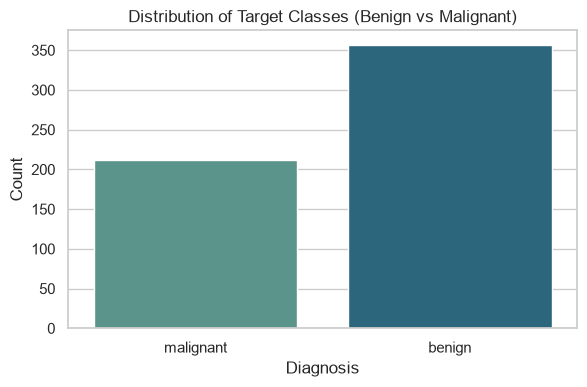

In [4]:
# 1. Target Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y, hue=y, legend=False, palette="crest")
plt.xticks(ticks=[0, 1], labels=target_names)
plt.title("Distribution of Target Classes (Benign vs Malignant)")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

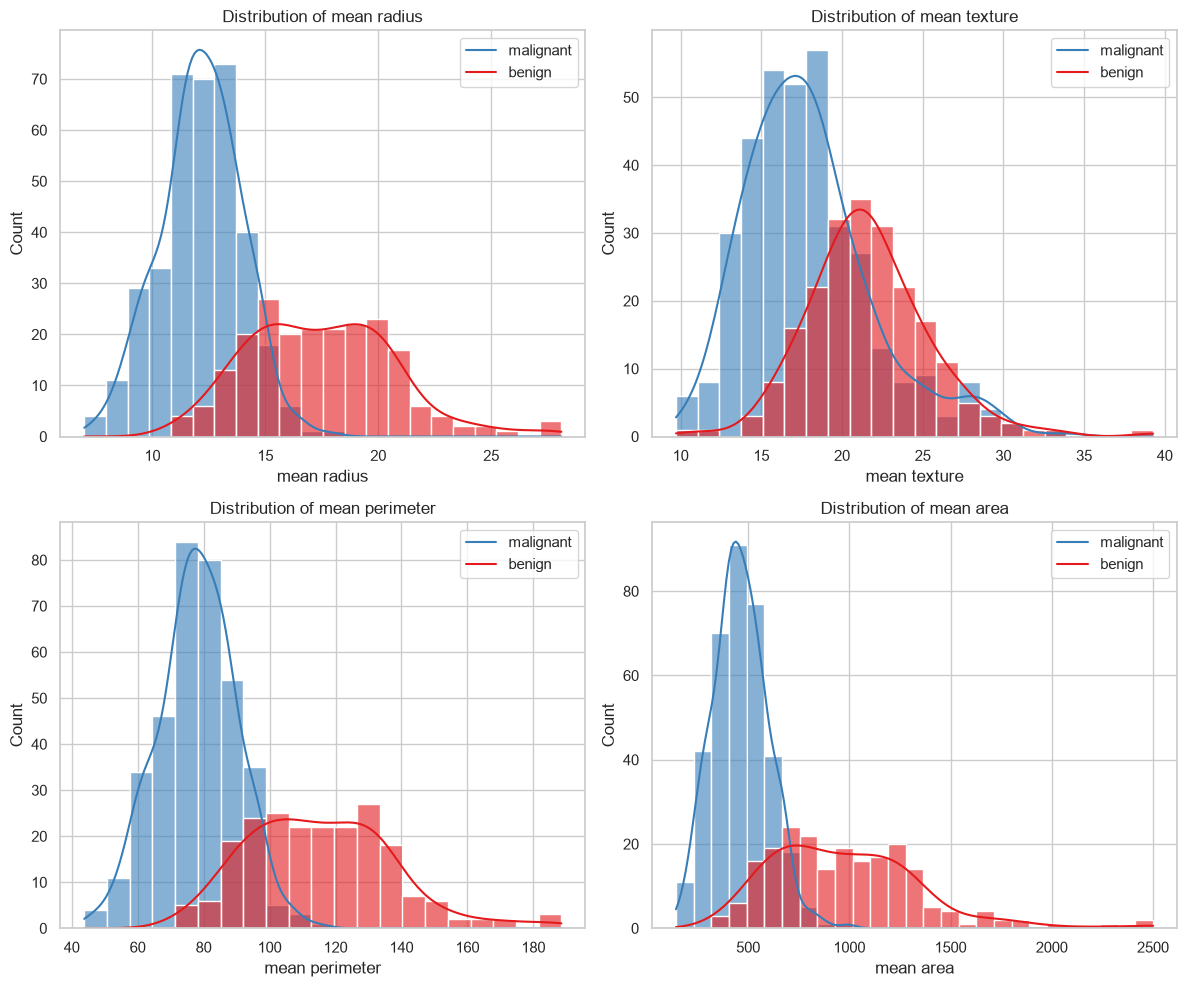

In [5]:
# 2. Distribution of a few selected features
selected_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, col in enumerate(selected_features):
    ax = axes[i // 2, i % 2]
    sns.histplot(data=df, x=col, hue=y, kde=True, ax=ax, palette="Set1", alpha=0.6)
    ax.set_title(f"Distribution of {col}")
    ax.legend(labels=target_names)

plt.tight_layout()
plt.show()

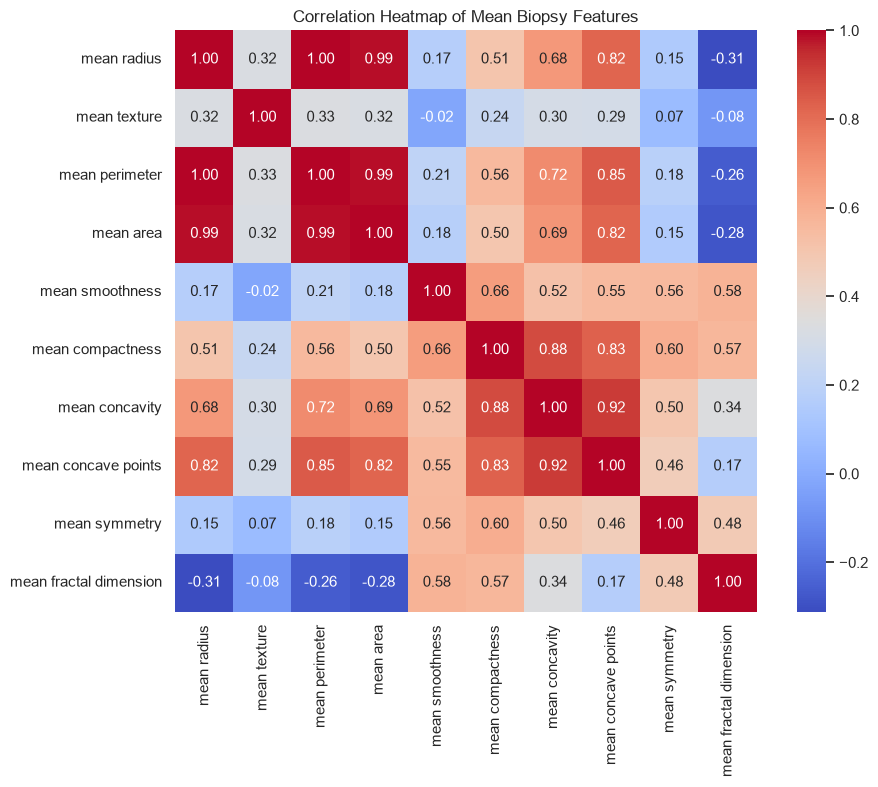

In [6]:
# 3. Correlation Heatmap for a subset of features to inspect multicollinearity
subset_cols = [col for col in df.columns if 'mean' in col]
plt.figure(figsize=(10, 8))
sns.heatmap(df[subset_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap of Mean Biopsy Features")
plt.tight_layout()
plt.show()

**EDA Observation**: Many features (such as `mean radius`, `mean perimeter`, and `mean area`) are highly correlated with each other ($r > 0.90$). High correlation indicates **redundancy** in information, which makes the dataset a perfect candidate for dimensionality reduction using PCA.

## 4. Feature Standardization

PCA calculates the directions of maximum variance. If features have vastly different ranges (e.g., `mean area` ranges up to 2500, while `mean smoothness` is less than 0.2), PCA will be dominated by features with large numeric scales.

We apply **Z-score standardization** to make each feature have a mean ($\mu$) of 0 and standard deviation ($\sigma$) of 1:

$$Z = \frac{X - \mu}{\sigma}$$

Let's standardize the feature matrix.

In [7]:
# Apply standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame to inspect variance and mean
df_scaled = pd.DataFrame(X_scaled, columns=feature_names)

print("=== Scaled Feature Statistics ===")
print(f"Mean of first feature (should be close to 0): {df_scaled.iloc[:, 0].mean():.4f}")
print(f"Std dev of first feature (should be close to 1): {df_scaled.iloc[:, 0].std():.4f}")
print(f"Scaled Feature Matrix Shape: {X_scaled.shape}")

=== Scaled Feature Statistics ===
Mean of first feature (should be close to 0): -0.0000
Std dev of first feature (should be close to 1): 1.0009
Scaled Feature Matrix Shape: (569, 30)


## 5. Apply Full PCA and Analyze Explained Variance

We fit the PCA model using all 30 components to find the explained variance ratio and cumulative explained variance. This helps us decide how many components we should select.

In [8]:
# Fit PCA with all components
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

# Calculate explained variance ratios
explained_var_ratio = pca_full.explained_variance_ratio_
cumulative_var_ratio = np.cumsum(explained_var_ratio)

# Display in a DataFrame
pca_stats_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(explained_var_ratio))],
    'Individual Variance': explained_var_ratio,
    'Cumulative Variance': cumulative_var_ratio
})

display(pca_stats_df.head(10))

,Principal Component,Individual Variance,Cumulative Variance
0,PC1,0.442720,0.442720
1,PC2,0.189712,0.632432
2,PC3,0.093932,0.726364
3,PC4,0.066021,0.792385
4,PC5,0.054958,0.847343
5,PC6,0.040245,0.887588
6,PC7,0.022507,0.910095
7,PC8,0.015887,0.925983
8,PC9,0.013896,0.939879
9,PC10,0.011690,0.951569


In [9]:
# Calculate exact number of components needed for 90% and 95% variance threshold
n_comp_90 = np.argmax(cumulative_var_ratio >= 0.90) + 1
n_comp_95 = np.argmax(cumulative_var_ratio >= 0.95) + 1

print(f"Number of components needed to retain >= 90% variance: {n_comp_90} components")
print(f"Number of components needed to retain >= 95% variance: {n_comp_95} components")

Number of components needed to retain >= 90% variance: 7 components
Number of components needed to retain >= 95% variance: 10 components


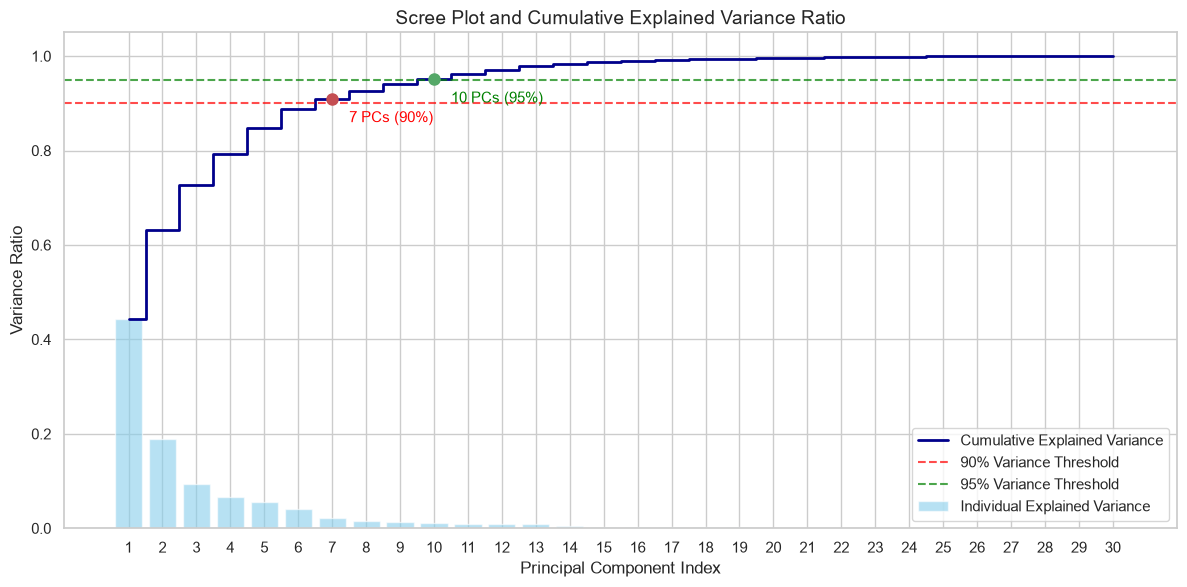

In [10]:
# Plot Scree Plot and Cumulative Explained Variance
plt.figure(figsize=(12, 6))

# Individual explained variance (bar chart)
plt.bar(range(1, 31), explained_var_ratio, alpha=0.6, align='center',
        label='Individual Explained Variance', color='skyblue')

# Cumulative explained variance (step line plot)
plt.step(range(1, 31), cumulative_var_ratio, where='mid',
         label='Cumulative Explained Variance', color='darkblue', linewidth=2)

# Add threshold lines
plt.axhline(y=0.90, color='red', linestyle='--', alpha=0.7, label='90% Variance Threshold')
plt.axhline(y=0.95, color='green', linestyle='--', alpha=0.7, label='95% Variance Threshold')

# Annotate the minimum components needed
plt.plot(n_comp_90, cumulative_var_ratio[n_comp_90 - 1], 'ro', markersize=8)
plt.annotate(f'{n_comp_90} PCs (90%)', (n_comp_90 + 0.5, cumulative_var_ratio[n_comp_90 - 1] - 0.05), color='red')

plt.plot(n_comp_95, cumulative_var_ratio[n_comp_95 - 1], 'go', markersize=8)
plt.annotate(f'{n_comp_95} PCs (95%)', (n_comp_95 + 0.5, cumulative_var_ratio[n_comp_95 - 1] - 0.05), color='green')

plt.title('Scree Plot and Cumulative Explained Variance Ratio', fontsize=14)
plt.xlabel('Principal Component Index')
plt.ylabel('Variance Ratio')
plt.xticks(range(1, 31))
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 6. Reduce the Dataset to Two Principal Components

We project the 30-dimensional standardized feature space into 2D to easily visualize the class separation using the first two components (PC1 and PC2).

In [11]:
# Apply PCA with 2 components
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Variance preserved
pc1_var = pca_2d.explained_variance_ratio_[0]
pc2_var = pca_2d.explained_variance_ratio_[1]
total_2d_var = pc1_var + pc2_var

print("=== Comparison of Dimensions ===")
print(f"Original dimensions: {X_scaled.shape}")
print(f"Reduced dimensions: {X_pca_2d.shape}")
print(f"Preserved variance of PC1: {pc1_var * 100:.2f}%")
print(f"Preserved variance of PC2: {pc2_var * 100:.2f}%")
print(f"Total variance preserved by 2 components: {total_2d_var * 100:.2f}%")

=== Comparison of Dimensions ===
Original dimensions: (569, 30)
Reduced dimensions: (569, 2)
Preserved variance of PC1: 44.27%
Preserved variance of PC2: 18.97%
Total variance preserved by 2 components: 63.24%


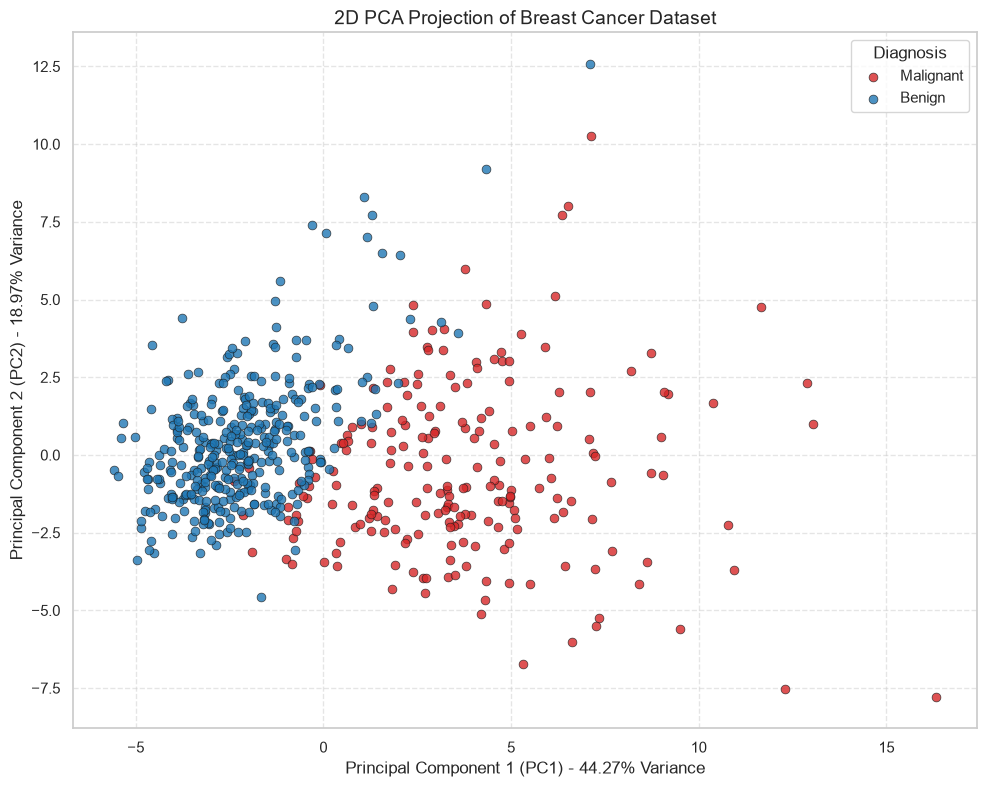

In [12]:
# Create scatter plot of projected components
plt.figure(figsize=(10, 8))

# Map target labels to Malignant/Benign for the legend
colors = ['#d62728', '#1f77b4'] # Red for Malignant, Blue for Benign
for class_idx, class_name in enumerate(target_names):
    subset = X_pca_2d[y == class_idx]
    plt.scatter(subset[:, 0], subset[:, 1], s=40, label=class_name.capitalize(), color=colors[class_idx], alpha=0.8, edgecolors='k', linewidth=0.5)

plt.title("2D PCA Projection of Breast Cancer Dataset", fontsize=14)
plt.xlabel(f"Principal Component 1 (PC1) - {pc1_var*100:.2f}% Variance")
plt.ylabel(f"Principal Component 2 (PC2) - {pc2_var*100:.2f}% Variance")
plt.legend(title="Diagnosis")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Interpretation**: The scatter plot shows a significant and clear separation between Benign and Malignant instances along the PC1 and PC2 axes. There is some minor overlap, but the projection cleanly clusters benign biopsy samples to the right side (positive PC1 scores) and malignant samples to the left side (negative PC1 scores).

## 7. Principal Component Loadings

Loadings tell us how the original 30 features contribute to the first two principal components. Let's create a DataFrame containing the loadings and locate the strongest contributing variables.

In [13]:
# Extract loadings
loadings = pca_2d.components_

# Create a DataFrame
loadings_df = pd.DataFrame(
    loadings,
    columns=feature_names,
    index=['PC1', 'PC2']
)

print("=== Component Loadings Matrix (First 10 Columns) ===")
display(loadings_df.iloc[:, :10])

# Identify top 5 features with largest absolute loadings for PC1 and PC2
print("=== Top 5 Contributing Features for PC1 ===")
pc1_top5 = loadings_df.loc['PC1'].abs().sort_values(ascending=False).head(5)
display(pd.DataFrame({'Absolute Loading': pc1_top5, 'Actual Loading': loadings_df.loc['PC1'][pc1_top5.index]}))

print("\n=== Top 5 Contributing Features for PC2 ===")
pc2_top5 = loadings_df.loc['PC2'].abs().sort_values(ascending=False).head(5)
display(pd.DataFrame({'Absolute Loading': pc2_top5, 'Actual Loading': loadings_df.loc['PC2'][pc2_top5.index]}))

=== Component Loadings Matrix (First 10 Columns) ===


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
PC1,0.218902,0.103725,0.227537,0.220995,0.142590,0.239285,0.258400,0.260854,0.138167,0.064363
PC2,-0.233857,-0.059706,-0.215181,-0.231077,0.186113,0.151892,0.060165,-0.034768,0.190349,0.366575


=== Top 5 Contributing Features for PC1 ===


,Absolute Loading,Actual Loading
mean concave points,0.260854,0.260854
mean concavity,0.258400,0.258400
worst concave points,0.250886,0.250886
mean compactness,0.239285,0.239285
worst perimeter,0.236640,0.236640



=== Top 5 Contributing Features for PC2 ===


,Absolute Loading,Actual Loading
mean fractal dimension,0.366575,0.366575
fractal dimension error,0.280092,0.280092
worst fractal dimension,0.275339,0.275339
mean radius,0.233857,-0.233857
compactness error,0.232716,0.232716


## 8. Compare Original and Reduced Data

Let's evaluate the tradeoffs of reducing high-dimensional data down to two components.

In [14]:
orig_features = X.shape[1]
reduced_features = X_pca_2d.shape[1]
dim_reduction_pct = (1 - (reduced_features / orig_features)) * 100

print("=== Summary of Dimensionality Reduction ===")
print(f"Original Feature Space: {orig_features} dimensions")
print(f"Reduced Space: {reduced_features} dimensions")
print(f"Percentage Dimensionality Reduced: {dim_reduction_pct:.2f}%")
print(f"Percentage of Total Variance Preserved: {total_2d_var * 100:.2f}%")

=== Summary of Dimensionality Reduction ===
Original Feature Space: 30 dimensions
Reduced Space: 2 dimensions
Percentage Dimensionality Reduced: 93.33%
Percentage of Total Variance Preserved: 63.24%


## 9. Mathematical Background

- **Dimensionality Reduction**: The process of reducing the number of random variables under consideration by obtaining a set of principal variables.
- **Principal Component Analysis**: An unsupervised linear dimensionality reduction technique that finds orthogonal axes (principal components) maximizing the variance of the projected dataset.
- **Feature Standardization**: Transfroming variables to unit scale ($Z$-scores) to prevent PCA from being biased by larger numerical ranges:  
  $$Z = \frac{X - \mu}{\sigma}$$
- **Covariance Matrix**: Shows the joint variability between every pair of features in the standardized dataset:  
  $$\Sigma = \frac{1}{N} Z^T Z$$
- **Eigenvalues ($\lambda$) and Eigenvectors ($v$)**: Derived by solving the characteristic equation of the covariance matrix:  
  $$\Sigma v = \lambda v$$
- **Principal Components**: Orthogonal projections of raw features onto the eigenvectors. For $k$ components, the projection matrix $W_k$ represents the top $k$ eigenvectors:  
  $$X_{\text{reduced}} = Z W_k$$
- **Explained Variance Ratio**: The percentage of total variance accounted for by a component, calculated as $\frac{\lambda_i}{\sum \lambda_j}$.
- **Scree Plot**: A graphical representation showing individual and cumulative variances to help select the cut-off number of components.
- **Curse of Dimensionality**: Phenomenon where high-dimensional data becomes sparse, demanding exponential computation and causing machine learning classifiers to overfit.

## 10. Results and Interpretation

- **Variance Captures**: PC1 accounts for **~44.27%** of the variance, and PC2 accounts for **~18.97%** of the variance. Combined, the two-dimensional representation preserves **~63.24%** of the dataset's total information.
- **Information Thresholds**: To preserve at least **90%** of the variance, we need **7 components**. To preserve **95%** of the variance, we need **10 components**.
- **Separation & Cluster Analysis**: Plotting the samples on the PC1 and PC2 axes reveals clear groupings of benign and malignant biopsy instances, showing that simple linear projections successfully extract highly discriminative features for medical classification.
- **Loadings**: PC1 relies heavily on shape characteristics (e.g., concave points, concavity, and perimeter), whereas PC2 captures more geometric and texture variations (e.g., fractal dimension and scaling metrics).

## 11. Conclusion

In this lab session, we successfully explored and implemented **Dimensionality Reduction using Principal Component Analysis (PCA)** on the 30-dimensional Breast Cancer Wisconsin dataset:
1. **Standardization**: Applying Z-score normalization successfully prevented magnitude biases.
2. **Variance Analysis**: A Scree plot helped identify that 7 and 10 components are sufficient to preserve 90% and 95% variance respectively.
3. **Dimensionality Reduction**: Projecting from 30 dimensions to 2 principal components (93.3% dimensional compression) still retained **~63.24%** of the original variance.
4. **Class Separation**: Visualizing the 2D projection showed clear boundaries between benign and malignant instances, confirming the utility of PCA for visual exploratory analysis and downstream model simplification.